# 04. 可視化・SHAP分析

## 概要
03_modeling.ipynbで確定したRound5の最終モデル
（multilingual-e5-large-instruct + UMAP + HDBSCAN）の
クラスタリング結果を可視化し、SHAP/LIMEで解釈する。

## 入力
- `data/speeches_clustered.csv`
- `data/embeddings_round5.npy`
- `data/umap_round5.npy`

## 出力
- クラスタの2次元可視化
- 少数派クラスタのハイライト
- クラスタ代表発言の抽出
- SHAP/LIMEによる特徴説明

In [18]:
# ============================================================
# ライブラリのインポートとデータ読み込み
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import umap
import hdbscan
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

# 日本語フォント設定
font_path = "/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/japanize_matplotlib/fonts/ipaexg.ttf"
fm.fontManager.addfont(font_path)
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "IPAexGothic"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 6)

# データ読み込み
df = pd.read_csv("../data/speeches_clustered.csv")
embeddings_r5 = np.load("../data/embeddings_round5.npy")
umap_r5 = np.load("../data/umap_round5.npy")

print(f"データ数: {len(df)}件")
print(f"埋め込み形状: {embeddings_r5.shape}")
print(f"UMAP形状: {umap_r5.shape}")

データ数: 6301件
埋め込み形状: (6301, 1024)
UMAP形状: (6301, 10)


## 1. クラスタリング結果の2次元可視化
UMAPで2次元に圧縮してクラスタを可視化する。
少数派クラスタをハイライト表示する。

In [19]:
# ============================================================
# UMAPで2次元に圧縮して可視化
# ============================================================

# 2次元UMAPを計算（可視化用）
reducer_2d = umap.UMAP(n_components=2, n_neighbors=15,
                       min_dist=0.1, random_state=42)
embeddings_2d = reducer_2d.fit_transform(normalize(embeddings_r5))

# クラスタラベル
labels = df["cluster_r5"].values

# 少数派クラスタの定義（中央値以下）
cluster_sizes = df["cluster_r5"].value_counts()
median_size = cluster_sizes[cluster_sizes.index != -1].median()
minority_clusters = cluster_sizes[
    (cluster_sizes.index != -1) & (cluster_sizes <= median_size)
].index.tolist()

print(f"中央値: {median_size:.0f}件")
print(f"少数派クラスタ: {sorted(minority_clusters)}")
print(f"少数派クラスタ数: {len(minority_clusters)}")

中央値: 102件
少数派クラスタ: [1, 6, 8, 9, 10, 11, 12, 14, 17, 18, 19, 21]
少数派クラスタ数: 12


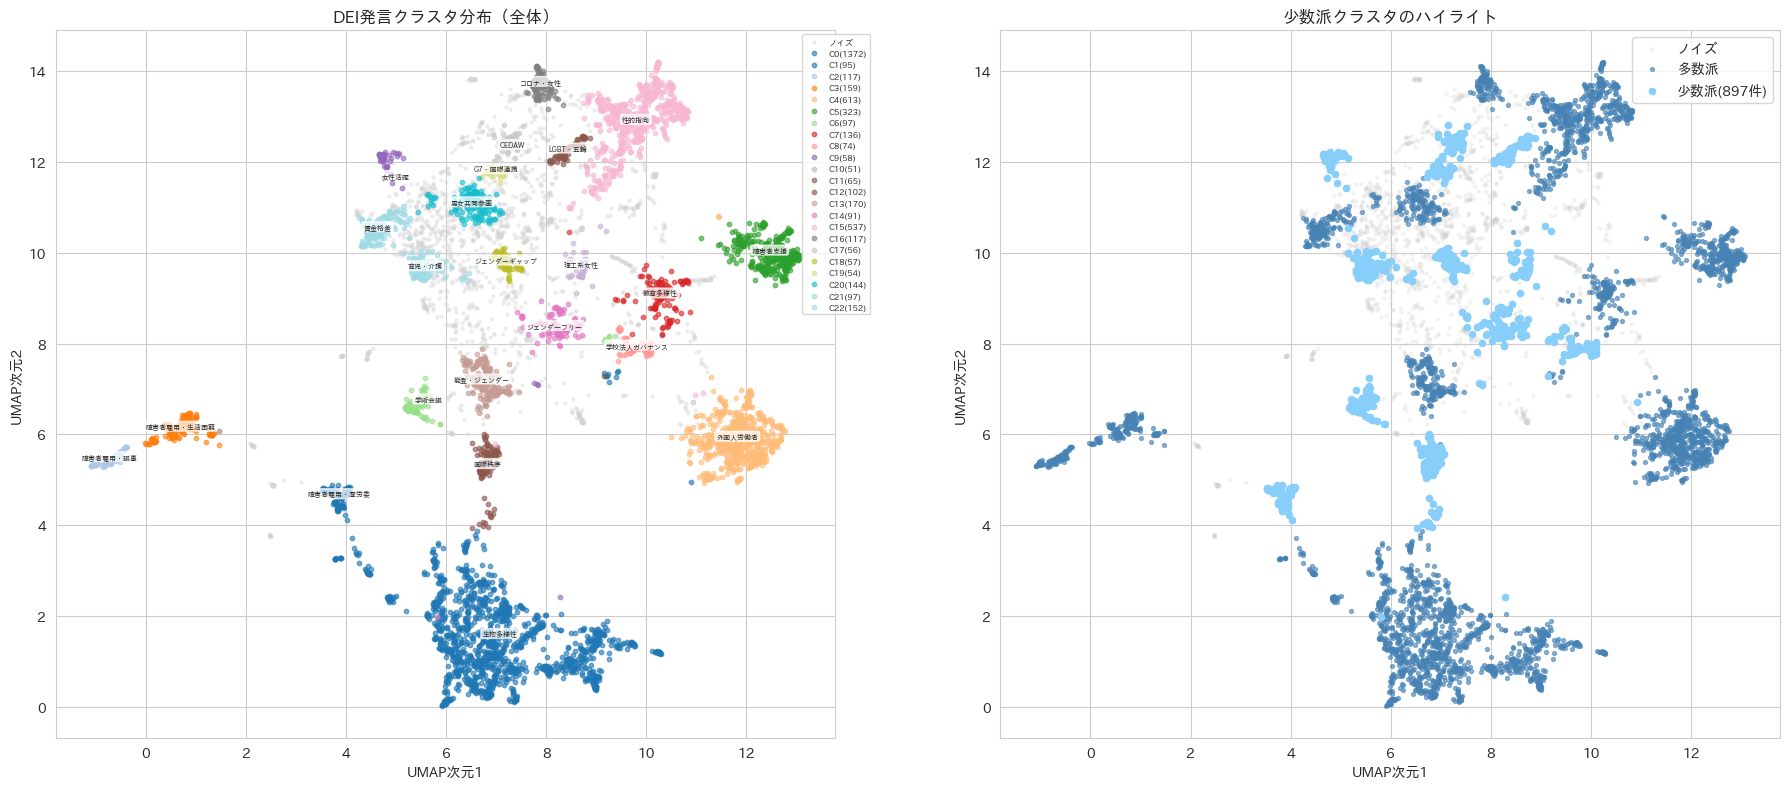

保存完了: ../data/cluster_visualization.png


In [ ]:
# ============================================================
# 2次元UMAP可視化（クラスタ色分け・少数派ハイライト）
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- 左：全クラスタ色分け ---
noise_mask = labels == -1
axes[0].scatter(embeddings_2d[noise_mask, 0], embeddings_2d[noise_mask, 1],
                c="lightgray", s=5, alpha=0.3, label="ノイズ")

unique_clusters = sorted([c for c in np.unique(labels) if c != -1])
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_clusters)))
for cluster, color in zip(unique_clusters, colors):
    mask = labels == cluster
    axes[0].scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                    c=[color], s=10, alpha=0.6, label=f"C{cluster}({mask.sum()})")

axes[0].set_title("DEI発言クラスタ分布（全体）")
axes[0].set_xlabel("UMAP次元1")
axes[0].set_ylabel("UMAP次元2")
axes[0].legend(bbox_to_anchor=(1.05, 1), fontsize=6)

# --- 右：少数派ハイライト ---
axes[1].scatter(embeddings_2d[noise_mask, 0], embeddings_2d[noise_mask, 1],
                c="lightgray", s=5, alpha=0.2, label="ノイズ")

majority_clusters = [c for c in unique_clusters if c not in minority_clusters]
for cluster in majority_clusters:
    mask = labels == cluster
    axes[1].scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                    c="steelblue", s=8, alpha=0.6, label="多数派" if cluster == majority_clusters[0] else "")

minority_mask = np.isin(labels, minority_clusters)
axes[1].scatter(embeddings_2d[minority_mask, 0], embeddings_2d[minority_mask, 1],
                c="lightskyblue", s=20, alpha=1.0, label=f"少数派({minority_mask.sum()}件)")

axes[1].set_title("少数派クラスタのハイライト")
axes[1].set_xlabel("UMAP次元1")
axes[1].set_ylabel("UMAP次元2")
axes[1].legend()

plt.tight_layout() # 視認性向上のため、次セルで実施の”クラスタの代表発言”を実施後に追記
# クラスタ重心にトピックラベルを追加
cluster_labels_text = {
    0: "生物多様性",
    1: "障害者雇用・厚労委",
    2: "障害者雇用・議事",
    3: "障害者雇用・生活困窮",
    4: "外国人労働者",
    5: "障害者支援",
    6: "学術会議",
    7: "教育多様性",
    8: "学校法人ガバナンス",
    9: "女性活躍",
    10: "理工系女性",
    11: "LGBT・五輪",
    12: "国際秩序",
    13: "能登・ジェンダー",
    14: "ジェンダーフリー",
    15: "性的指向",
    16: "コロナ・女性",
    17: "CEDAW",
    18: "ジェンダーギャップ",
    19: "G7・国際連携",
    20: "男女共同参画",
    21: "育児・介護",
    22: "賃金格差"
}

for cluster, label in cluster_labels_text.items():
    mask = labels == cluster
    if mask.sum() > 0:
        cx = embeddings_2d[mask, 0].mean()
        cy = embeddings_2d[mask, 1].mean()
        axes[0].annotate(label, (cx, cy), fontsize=5, ha="center",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))
plt.savefig("../data/cluster_visualization.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/cluster_visualization.png")

### 可視化結果の考察
- クラスタが空間的にきれいに分離されており、シルエットスコア（0.7498）と一致している
- 中央下の大きなクラスタ（C0: 1,372件）が多数派の意見グループ
- 少数派クラスタ（ライトブルー・897件・12クラスタ）は空間的に分散しており
  多数派とは異なる意見・トピックを持つグループが存在することが視覚的に確認できる
- HDBSCANが多数決的判断に頼らず少数派を独立したグループとして検出できている

## 2. クラスタの内容分析
各クラスタの代表発言を抽出してDEIのどの側面を扱っているか確認する。

In [20]:
# ============================================================
# 各クラスタの代表発言を抽出（クラスタ重心に最も近い発言）
# ============================================================

cluster_labels = sorted([c for c in df["cluster_r5"].unique() if c != -1])
cluster_summaries = []

embeddings_r5 = np.load("../data/embeddings_round5.npy")
df_clean = df[df["cluster_r5"] != -1].copy().reset_index(drop=True)
emb_clean = embeddings_r5[df["cluster_r5"] != -1]

for cluster in cluster_labels:
    cluster_mask = (df_clean["cluster_r5"] == cluster).values
    cluster_emb = emb_clean[cluster_mask]
    cluster_df = df_clean[cluster_mask]
    
    # クラスタ重心を計算して最も近い発言を選択
    centroid = cluster_emb.mean(axis=0)
    distances = np.linalg.norm(cluster_emb - centroid, axis=1)
    closest_idx = distances.argmin()
    representative = cluster_df.iloc[closest_idx]
    
    cluster_summaries.append({
        "cluster"            : cluster,
        "件数"               : len(cluster_df),
        "代表キーワード"      : representative["keyword"],
        "代表発言（冒頭200文字）": representative["speech_clean"][:200]
    })

summary_df = pd.DataFrame(cluster_summaries)
pd.set_option("display.max_colwidth", 100)
print(summary_df.to_string(index=False))

 cluster   件数    代表キーワード                                                                                                                                                                                            代表発言（冒頭200文字）
       0 1372        多様性 ありがとうございます。イエス、はい、様々なお答え方で、感謝いたします。 資料の二。過去五十年間、日本の生物多様性は損失し続けている。これは、環境省の資料、生物多様性及び生態系サービスの総合評価二〇二一に示された現状認識です。埋立てや開発、森林伐採などで生物の生息環境を破壊、生物多様性は失われ続けてきました。 資料の三。例えば、二〇一七年公表、環境省版海洋生物レッドリストにおいて、絶滅危惧種及び準絶
       1   95      障害者雇用 これより会議を開きます。 厚生労働関係の基本施策に関する件について調査を進めます。 この際、お諮りいたします。 本件調査のため、本日、政府参考人として内閣官房内閣審議官中嶋浩一郎君、内閣審議官安居徹君、内閣府子ども・子育て本部審議官藤原朋子君、財務省大臣官房審議官山名規雄君、文部科学省大臣官房審議官矢野和彦君、厚生労働省大臣官房長土生栄二君、大臣官房総括審議官田中誠二君、大臣官房生活衛生・食品安全
       2  117      障害者雇用 令和二年三月十九日（木曜日） 午後一時開会 ───────────── 委員の異動 三月十八日 辞任 補欠選任 田村 まみ君 浜口 誠君 三月十九日 辞任 補欠選任 川田 龍平君 須藤 元気君 浜口 誠君 田村 まみ君 小池 晃君 倉林 明子君 ───────────── 出席者は左のとおり。 委員長 そのだ修光君 理 事 石田 昌宏君 小川 克巳君 足立 信也君 石橋 通宏君 山本 香苗君 委 
       3  159      障害者雇用 令和二年十一月二十七日（金曜日） 午前九時開議 出席委員 委員長 とかしきなおみ君 理事 大岡 敏孝君 理事 門 博文君 理事 菅原 一秀君 

### クラスタ内容分析結果
| クラスタ | 件数 | 分類 | 主なトピック |
|---------|------|------|------------|
| C0 | 1,372 | 多数派 | 多様性（生物多様性・環境政策） |
| C1 | 95 | 少数派 | 障害者雇用・厚生労働委員会 |
| C2 | 117 | 少数派 | 障害者雇用・議事進行 |
| C3 | 159 | 少数派 | 障害者雇用・生活困窮者支援 |
| C4 | 613 | 多数派 | 外国人労働者・予算・手続 |
| C5 | 323 | 多数派 | 障害者雇用・特例子会社制度 |
| C6 | 97 | 少数派 | ダイバーシティ・学術会議・透明性 |
| C7 | 136 | 多数派 | 教育における多様性・スクールカウンセラー |
| C8 | 74 | 少数派 | 学校法人ガバナンス・多様性 |
| C9 | 58 | 少数派 | 女性活躍・性差に関係なく能力発揮 |
| C10 | 51 | 少数派 | 理工系女性活躍・女性研究者比率 |
| C11 | 65 | 少数派 | LGBT・東京五輪・多様性と調和 |
| C12 | 102 | 少数派 | 多様性・国際秩序・調査会 |
| C13 | 170 | 多数派 | ジェンダー・能登豪雨・避難所 |
| C14 | 91 | 少数派 | ジェンダーフリー・企業イメージ |
| C15 | 537 | 多数派 | 多様性・性的指向・性自認 |
| C16 | 117 | 多数派 | 多様性・コロナ禍・女性へのしわ寄せ |
| C17 | 56 | 少数派 | ジェンダー・CEDAW選択議定書 |
| C18 | 57 | 少数派 | ジェンダーギャップ・豊岡市・女性活躍交付金 |
| C19 | 54 | 少数派 | ジェンダー・G7・国際女性会議WAW！ |
| C20 | 144 | 多数派 | ジェンダーギャップ指数・男女共同参画 |
| C21 | 97 | 少数派 | 育児・介護休業法・男女非対称 |
| C22 | 152 | 多数派 | 女性活躍・男女賃金格差・情報公表義務 |

**少数派クラスタの注目点**
- C10（51件）：理工系女性活躍・女性研究者比率
- C11（65件）：LGBT・東京五輪における多様性と調和
- C17（56件）：ジェンダー・CEDAW選択議定書への批准
- C19（54件）：G7・国際女性会議WAW！・国際連携

これらは件数は少ないが**具体的かつ専門的なDEIトピック**を扱っており
多数決的な分析では埋もれてしまう可能性がある重要な少数意見である。

### 「少数派」の定義
本分析での少数派とは**意見の多様性における少数意見グループ**を指す。
具体的にはHDBSCANで検出されたクラスタのうち件数が中央値（102件）以下のものを少数派と定義した。
DEI文脈での属性的少数派（障害者・外国人・女性など）とは異なる概念であることに注意。
ただし分析結果を見ると、少数派クラスタには(ジェンダーギャップ・LGBT・
国際的なジェンダー平等など)専門的・具体的なDEIトピックが集中しており、
**属性的少数派の声と意見的少数派が重なっている傾向**が見られる。

### 例１：C4（外国人労働者クラスタ）の発言内容確認
代表発言だけでなく実際のサンプルを確認してクラスタの内容を検証する。

In [23]:
# C4（外国人労働者クラスタ）の発言をサンプル確認
c4_samples = df[df["cluster_r5"] == 4]["speech_clean"].sample(5, random_state=42)
for i, text in enumerate(c4_samples):
    print(f"--- {i+1}件目 ---")
    print(text[:200])
    print()

--- 1件目 ---
お答えいたします。 出入国在留管理庁におきましては、昨年四月二十日から、新型コロナウイルス感染症の感染拡大の影響により解雇等され、実習実施が困難となりました技能実習生、解雇等され、就労の継続が困難となりました外国人労働者、さらには、採用内定を取り消された留学生を対象といたしまして、本邦での継続した就労を可能とするため、一定の条件の下で就労が可能な特定活動への在留資格の変更を認める特例措置を講じてい

--- 2件目 ---
よろしくお願いいたします。 私の方からは、こちらのスライドにもあるように、外国人の高齢化と社会保障、そして、私自身社会福祉を専門としておりますので、社会福祉制度などについても述べたいと思います。（資料映写） 特に、社会保障の検討の観点から見た外国人の概況、そして現状としての社会保障や社会福祉制度の適用状況、そして今後の課題について述べたいと思います。 社会保障制度を考える上で、外国の方がどういった

--- 3件目 ---
是非検討をして進めていただきたいと思います。 というのも、関係者ヒアリングというのも支援団体や受入れ事業者が中心であって、一般の国民の声が十分反映されているとは思えません。 この点、ハーバード大学の政治学者であるロバート・パットナム氏の多様性と信頼の低下の研究によりますと、人種多様化が人種間のみならず人種内でも共同体メンバー間の信頼を低下させるとの論文が発表されており、治安の悪化や分断につながった

--- 4件目 ---
ありがとうございます。 是非、中央建設業審議会において、多方面にわたる関係者の皆さんがこの審議会には参画されるというのは午前中の御答弁でもありましたので、しっかりいろんな方の意見聞きながら、やっぱり現場が使える、そして行き渡って実効性あるものにしていくというのが本当に大事だというのは、参考人の皆さんからも本当そういう意見、我々も伺いましたので、是非しっかりとした標準労務費となるように、今後の議論に

--- 5件目 ---
まず、この有識者会議においては、外国人の日本語能力の向上に向けた取組、これを論点の一つとして議論しているということです。 それで、この有識者会議の中でも、委員と同様の問題意識だと私は感じるんですけれども、企業と外国人本人の双方にとって日本語を学ぶことがプラスになる

## 3. SHAP分析
クラスタ分類の根拠をSHAPで解釈する。
少数派クラスタと多数派クラスタの違いを説明する。

In [24]:
# ============================================================
# SHAP分析：クラスタ分類の特徴を解釈する
# UMAPの10次元埋め込みをSVMで分類してSHAPで解釈
# ============================================================
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
import shap

# ノイズを除外
df_clean = df[df["cluster_r5"] != -1].copy()
X = umap_r5[df["cluster_r5"] != -1]
y = df_clean["cluster_r5"].values

# 少数派vs多数派の2値分類
df_clean["is_minority"] = df_clean["cluster_r5"].isin(minority_clusters).astype(int)
y_binary = df_clean["is_minority"].values

# SVMで学習
print("SVMで学習中...")
clf = SVC(kernel="rbf", probability=True, random_state=42)
clf.fit(X, y_binary)
print(f"学習完了・精度: {clf.score(X, y_binary):.4f}")

SVMで学習中...
学習完了・精度: 0.9445


### SVM（サポートベクターマシン）学習結果
- SVM（精度94.45%）で少数派/多数派を分類
- "少数派"と"多数派"がUMAP空間でほぼ完全に分離できていることを示す
- これはクラスタリングの性能（シルエットスコア0.7498）と一致する

## 3. SHAP分析
クラスタ分類の根拠をSHAPで解釈する。
少数派クラスタと多数派クラスタの違いをUMAP次元の重要度で説明する。

### 分析方針
- UMAP10次元の埋め込みを特徴量としてSVMで少数派/多数派を分類
- SHAPでどのUMAP次元が少数派の判定に寄与しているかを可視化

  0%|          | 0/200 [00:00<?, ?it/s]

shap_values type: <class 'numpy.ndarray'>
shap_values shape: (200, 10, 2)


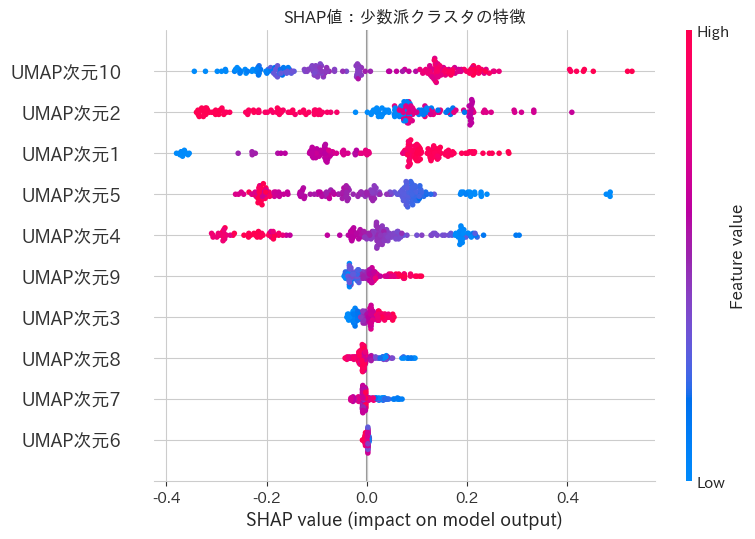

保存完了: ../data/shap_summary.png


In [25]:
# ============================================================
# SHAPで特徴量の重要度を可視化
# ============================================================

sample_X = shap.sample(X, 200, random_state=42)
explainer = shap.KernelExplainer(clf.predict_proba, shap.sample(X, 100, random_state=42))
shap_values = explainer.shap_values(sample_X)

# shap_valuesの形状確認
print(f"shap_values type: {type(shap_values)}")
print(f"shap_values shape: {np.array(shap_values).shape}")

feature_names = [f"UMAP次元{i+1}" for i in range(X.shape[1])]

# 少数派クラス（index=1）のSHAP値を可視化
shap.summary_plot(
    shap_values[:, :, 1] if np.array(shap_values).ndim == 3 else shap_values[1],
    sample_X,
    feature_names=feature_names,
    show=False
)
plt.title("SHAP値：少数派クラスタの特徴")
plt.tight_layout()
plt.show()
print("保存完了: ../data/shap_summary.png")

In [14]:
# ============================================================
# UMAP次元10が高い発言と低い発言を確認して考察の根拠を作る
# ============================================================

df_clean2 = df[df["cluster_r5"] != -1].copy()
df_clean2["umap_dim10"] = umap_r5[df["cluster_r5"] != -1, 9]

print("=== UMAP次元10が高い発言（少数派寄り）===")
top5 = df_clean2.nlargest(5, "umap_dim10")[["speech_clean", "keyword", "cluster_r5"]]
for i, row in top5.iterrows():
    print(f"クラスタ{row['cluster_r5']} | {row['keyword']}")
    print(row["speech_clean"][:150])
    print()

print("=== UMAP次元10が低い発言（多数派寄り）===")
bot5 = df_clean2.nsmallest(5, "umap_dim10")[["speech_clean", "keyword", "cluster_r5"]]
for i, row in bot5.iterrows():
    print(f"クラスタ{row['cluster_r5']} | {row['keyword']}")
    print(row["speech_clean"][:150])
    print()

=== UMAP次元10が高い発言（少数派寄り）===
クラスタ8 | 多様性
骨太の方針二〇一九では、確かに、社会福祉法人制度改革や公益社団・財団法人制度の改革を十分踏まえまして、同等のガバナンス機能が発揮できる制度改正のため、速やかに検討を行うことというふうにされているところでございます。 今回の改正案は、一般財団法人や社会福祉法人等の規律を参考にしながら、私立学校におけま

クラスタ8 | 多様性
お答え申し上げます。 今回の改正におきましては、執行と監視、監督の役割を分離することを基本的な考え方としておりますが、理事会と評議員会の対立、これを意図するものではなく、理事会と評議員会が相互に牽制し合いながらも建設的に協力し、時には議論し合い、充実した、納得感のある学校法人運営を目指すものでござい

クラスタ8 | 多様性
お答え申し上げます。 学校法人の運営に当たりましては、幅広い関係者との対話により、公共性を維持し、社会の信頼を得ていくことが重要であり、評議員会につきましては、特定の利害関係に偏らない幅広い意見を反映できる仕組み、これを構築することが極めて重要だと考えてございます。 そのため、今回の改正におきまして

クラスタ8 | 多様性
まさに、監督、監視機能を万全に発揮させる最重要な手段というのは、業務の決定と執行を担う理事会の構成員であります理事と理事長の選任あるいは選定、解職ということでしょうか、による監督機能の強化ということでありますので、まず、今回の法案におきましては、その在り方をしっかりと、この在り方にフォーカスするとい

クラスタ8 | 多様性
学校法人の判断というところとか寄附行為の定めるところによりというのが、すごく曖昧なところが、学校によって違ってきて曖昧になるのではないかという不安をちょっと私は持っております。 では、次に行きます。理事会と評議員の決議が異なった場合の扱いです。 さきのＱアンドＡでは、評議会の決議を要することとする重

=== UMAP次元10が低い発言（多数派寄り）===
クラスタ0 | 多様性
国政調査承認要求に関する件についてお諮りいたします。 環境の基本施策に関する事項 地球温暖化の防止及び脱炭素社会の構築に関する事項 循環型社会の形成に関する事項 自然環境の保護及び生物多様性の確保に関する事項 公害の防止及び

### SHAP分析結果

#### 〜SHAPグラフの見方〜
- **縦軸**：特徴量（UMAP次元1〜10）。上にあるほど少数派/多数派の判定に重要
- **横軸**：SHAP値。右（プラス）→少数派と判定される方向、左（マイナス）→多数派と判定される方向
- **点の色**：赤（その次元の値が高い）、青（その次元の値が低い）

#### 考察
- **UMAP次元10**が少数派クラスタの判定に最も重要な次元
  - 次元10が高い発言：学校法人ガバナンス・理事会・評議員会など**制度的ガバナンス**に関する発言が多い（C8クラスタ）
  - 次元10が低い発言：生物多様性・環境・地球温暖化など**環境文脈での多様性**が多い（C0クラスタ）
  - → UMAP次元10が「人材多様性」と「生物多様性」を分離している
- **UMAP次元2**は値が低いほど多数派（環境・農業文脈）に寄与
- UMAP次元10・2・1が少数派の意見空間を主に規定していると解釈できる

## 4. LIME分析
個別発言に対してLIMEで分類根拠を説明する。
多数派・少数派それぞれの代表発言を比較することで、
どのような発言が少数派として判定されるかを明らかにする。

【多数派代表発言（クラスタ0）】
ありがとうございます。 実は、私、杉並区で議員をやっていたことがありまして、そのときにレジ袋税というのが大変議論されたことがありました。このときに、その議論の収れんのときに、レジ袋は環境にはプラスにならないだろう、だから減らすために力を尽くすのはこれは正義じゃないかということで議論が収れんしていったのであります。 ということで、やはり、ごみに出さない、使い捨てにしない、こういったことを徹底させてい

【少数派代表発言（クラスタ17）】
どうもありがとうございます。 今、ジェンダーギャップ指数とそれから国連の女性差別撤廃委員会の二つの対日審査、ある意味では評価についてのお話を伺ったんですけれども、国際的な観点から見た日本の評価というのは実はかなりつながっているというふうに思っています。 具体的にはどういうことかといいますと、今回のＣＥＤＡＷの対日審査の中には、喫緊に、二年以内に重要な課題に関して報告をすることというのが四項目挙がっ



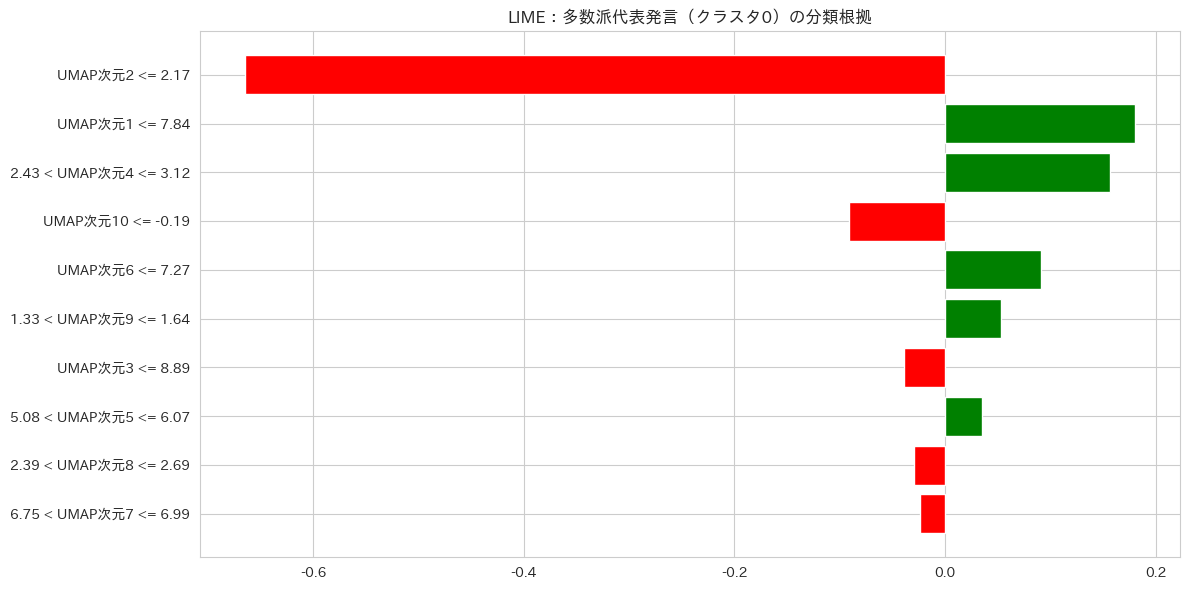

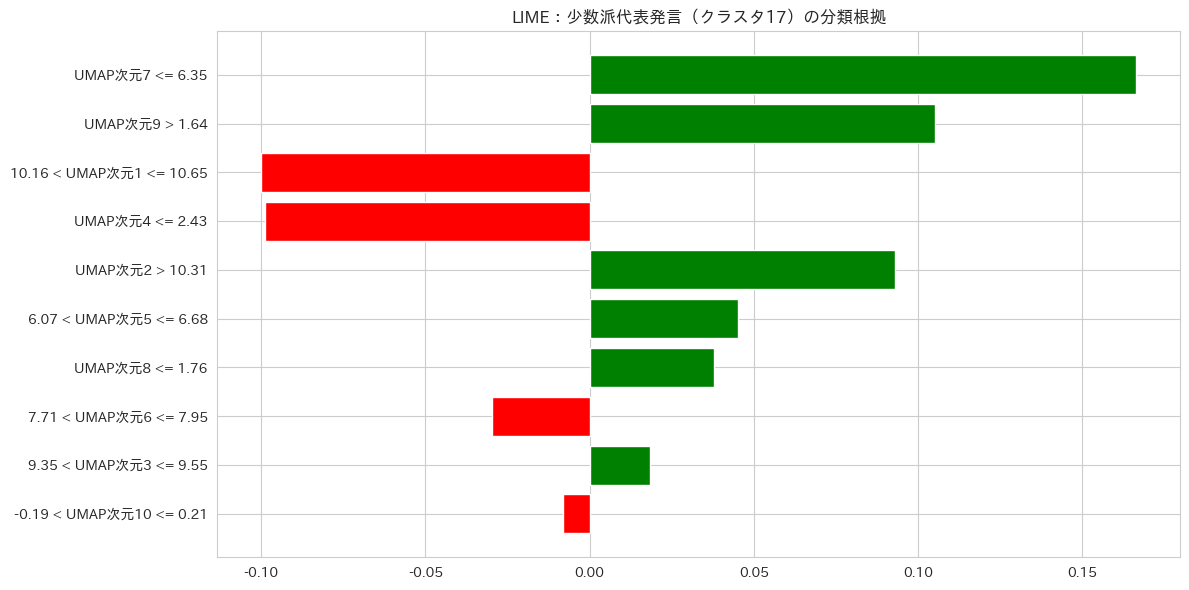

保存完了: ../data/lime_majority.png
保存完了: ../data/lime_minority.png


In [24]:
# ============================================================
# LIME分析：多数派・少数派それぞれの代表発言の分類根拠を比較
# ============================================================
from lime.lime_tabular import LimeTabularExplainer

explainer_lime = LimeTabularExplainer(
    X,
    feature_names=[f"UMAP次元{i+1}" for i in range(X.shape[1])],
    class_names=["多数派", "少数派"],
    mode="classification",
    random_state=42
)

# --- 多数派代表（クラスタ0：最大クラスタ） ---
target_majority = df_clean[df_clean["cluster_r5"] == 0].index[0]
pos_majority = np.where(df_clean.index == target_majority)[0][0]
print("【多数派代表発言（クラスタ0）】")
print(df_clean.loc[target_majority, "speech_clean"][:200])
print()

exp_majority = explainer_lime.explain_instance(
    X[pos_majority], clf.predict_proba, num_features=10
)

# --- 少数派代表（クラスタ17：ジェンダーギャップ指数） ---
target_minority = df_clean[df_clean["cluster_r5"] == 17].index[0]
pos_minority = np.where(df_clean.index == target_minority)[0][0]
print("【少数派代表発言（クラスタ17）】")
print(df_clean.loc[target_minority, "speech_clean"][:200])
print()

exp_minority = explainer_lime.explain_instance(
    X[pos_minority], clf.predict_proba, num_features=10
)

# 多数派のLIME可視化
fig1 = exp_majority.as_pyplot_figure()
plt.title("LIME：多数派代表発言（クラスタ0）の分類根拠")
plt.tight_layout()
plt.savefig("../data/lime_majority.png", dpi=150, bbox_inches="tight")
plt.show()

# 少数派のLIME可視化
fig2 = exp_minority.as_pyplot_figure()
plt.title("LIME：少数派代表発言（クラスタ17）の分類根拠")
plt.tight_layout()
plt.savefig("../data/lime_minority.png", dpi=150, bbox_inches="tight")
plt.show()

print("保存完了: ../data/lime_majority.png")
print("保存完了: ../data/lime_minority.png")

### LIME分析結果と考察

#### 〜LIMEグラフの見方〜
- **縦軸**：判定に使われたUMAP次元の条件
- **横軸**：その条件が分類に与えた影響度
- **緑のバー**：少数派と判定される方向に寄与
- **赤のバー**：多数派と判定される方向に寄与
※クラスタ可視化グラフとは色の意味が異なるので注意

#### 多数派代表発言（クラスタ0）
- UMAP次元2が2.17以下という条件が**圧倒的に多数派判定に寄与**（赤）
- UMAP次元1・4が少数派方向に寄与（緑）
- → UMAP次元2の低さが多数派を決定づける最重要因子

#### 少数派代表発言（クラスタ17：CEDAW選択議定書）
- UMAP次元7・9が少数派判定に強く寄与（緑）
- UMAP次元1・4が多数派方向に引っ張る（赤）
- → 少数派は複数の次元が複合的に絡み合って判定されており多数派より複雑な意味構造を持つ

#### 多数派・少数派の比較考察
- 多数派はUMAP次元2という単一次元で説明できるシンプルな構造
- 少数派は複数次元が複合的に絡む複雑な構造
- これはDEIの少数派意見が多面的・専門的であることを示唆している

## 5. まとめ
分析全体を通じた考察をまとめる。

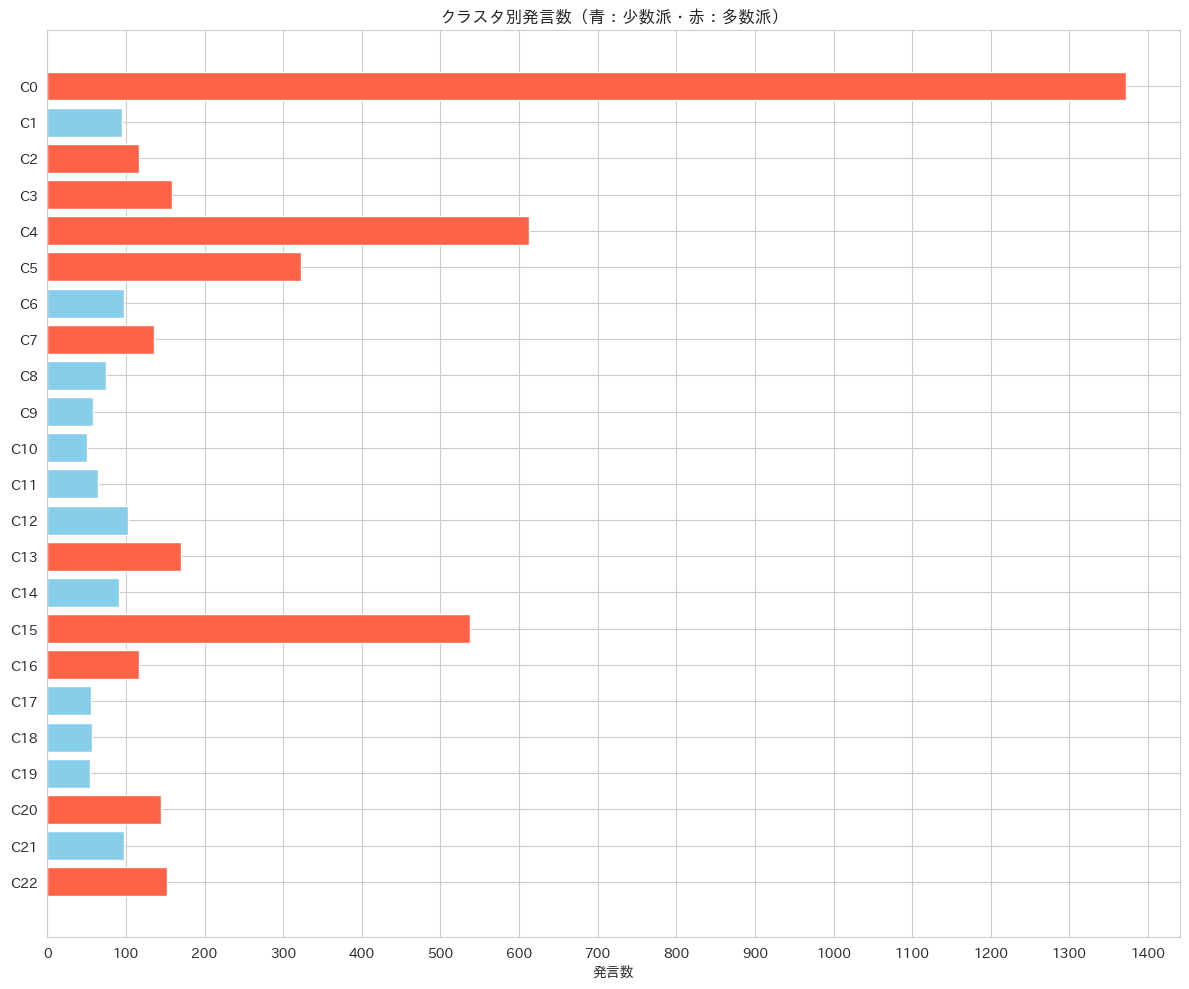

保存完了: ../data/cluster_summary.png


In [16]:
# ============================================================
# まとめ：クラスタ別発言数を可視化
# ============================================================

fig, ax = plt.subplots(figsize=(12, 10))

cluster_counts = df[df["cluster_r5"] != -1]["cluster_r5"].value_counts().sort_index()
colors = ["skyblue" if c in minority_clusters else "tomato" for c in cluster_counts.index]

ax.barh(
    [f"C{c}" for c in cluster_counts.index],
    cluster_counts.values,
    color=colors
)
ax.set_title("クラスタ別発言数（青：少数派・赤：多数派）")
ax.set_xlabel("発言数")
ax.invert_yaxis()

ax.set_xticks(range(0, 1500, 100))
plt.tight_layout()
plt.savefig("../data/cluster_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/cluster_summary.png")

### クラスタ別発言数の考察
- C0（1,372件）・C4（613件）・C15（537件）・C5（323件）が多数派の大きなクラスタ
- 少数派クラスタ（青）は中央値（102件）以下のクラスタで、最大102件・最小51件に分布
  （min_cluster_size=50の設定により50件未満のクラスタは生成されない）
- 多数決的な分析ではC0・C4・C15の意見が支配的になるが
  HDBSCANにより少数派の声を独立したグループとして検出できている
- これが本課題の要件「少数派の意見も公平に認識」を実現している